In [4]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import matplotlib.pyplot as plt 

# 1. load data hasil feature engineering
df = pd.read_parquet('../data/processed/train_features.parquet')

# 2. Time-based Train/Validation Split
# Split data 3 bulan terakhir (Oktober - Desember) sebagai data uji (validasi)
split_date = '2017-10-01'

train = df[df['date'] < split_date].copy()
val = df[df['date'] >= split_date].copy()

print(f"Jumlah data latih (Train): {len(train):,} baris")
print(f"Jumlah data uji (Val)    : {len(val):,} baris")

# 3. Menentukan fitur(X) dan target(Y)
features = [
    'store', 'item', 'day_of_week', 'is_weekend',
    'day_of_month', 'month', 'year',
    'sales_lag_1', 'sales_lag_7', 'sales_lag_28',
    'rolling_mean_7', 'rolling_std_7'
]
target = 'sales'

X_train, y_train = train[features], train[target]
X_val, y_val = val[features], val[target]

Jumlah data latih (Train): 853,000 baris
Jumlah data uji (Val)    : 46,000 baris


In [5]:
# --- MODEL 1: BASELINE (NAIVE FORECAST) ---
# Logika: Prediksi penjualan hari ini sama dengan penjualan 7 hari sebelumnya (lag 7)
baseline_preds = val['sales_lag_7']

mae_base = mean_absolute_error(y_val, baseline_preds)
rmse_base = root_mean_squared_error(y_val, baseline_preds)

print(f"[BASELINE - Minggu Lalu] MAE: {mae_base:.2f}, RMSE: {rmse_base:.2f}")

# --- MODEL 2: LIGHTGBM  REGRESSOR ---
# Mengatur depth tree dan jumlah estimators untuk menghindari overfitting
model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)

# Melatih model dengan early stopping (berhenti jika error di data uji tidak membaik selama 50 iterasi)
model.fit(
    X_train, y_train,
    eval_set = [(X_val, y_val)],
    callbacks = [lgb.early_stopping(stopping_rounds=50, verbose=100)]
)

lgb_preds = model.predict(X_val)

mae_lgb = mean_absolute_error(y_val, lgb_preds)
rmse_lgb = root_mean_squared_error(y_val, lgb_preds)

print(f"\n[LIGHTBGM Model]  MAE: {mae_lgb:.2f} | RMSE: {rmse_lgb:.2f}")
improvement = (mae_base - mae_lgb) / mae_base * 100
print(f"Peningkatan akurasi (penurunan error MAE): {improvement:.2f}%")

[BASELINE - Minggu Lalu] MAE: 9.08, RMSE: 12.05


d:\Sem 5\Demand-Forecasting-Inventory\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011698 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1200
[LightGBM] [Info] Number of data points in the train set: 853000, number of used features: 12
[LightGBM] [Info] Start training from score 52.492708
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's l2: 62.5368

[LIGHTBGM Model]  MAE: 6.11 | RMSE: 7.91
Peningkatan akurasi (penurunan error MAE): 32.69%


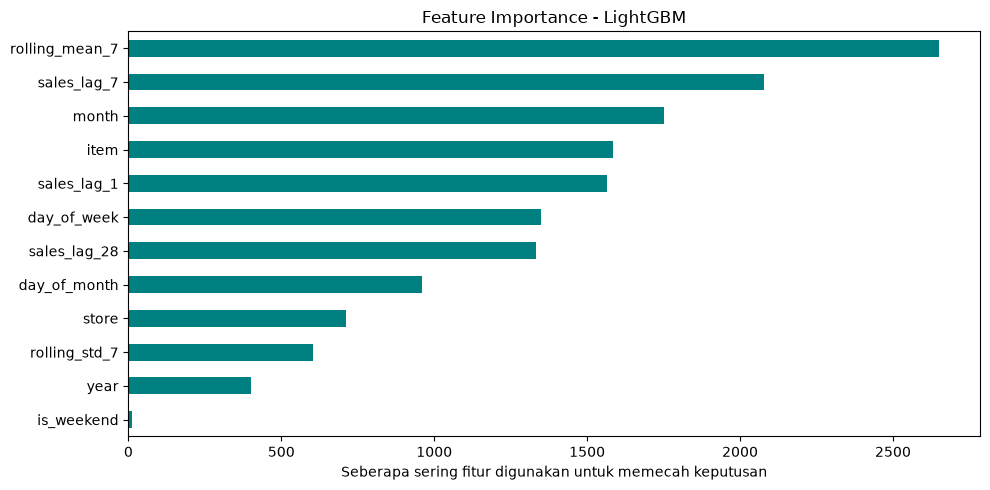

File val_predictions.parquet berhasil disimpan! Ukuran: (46000, 15)


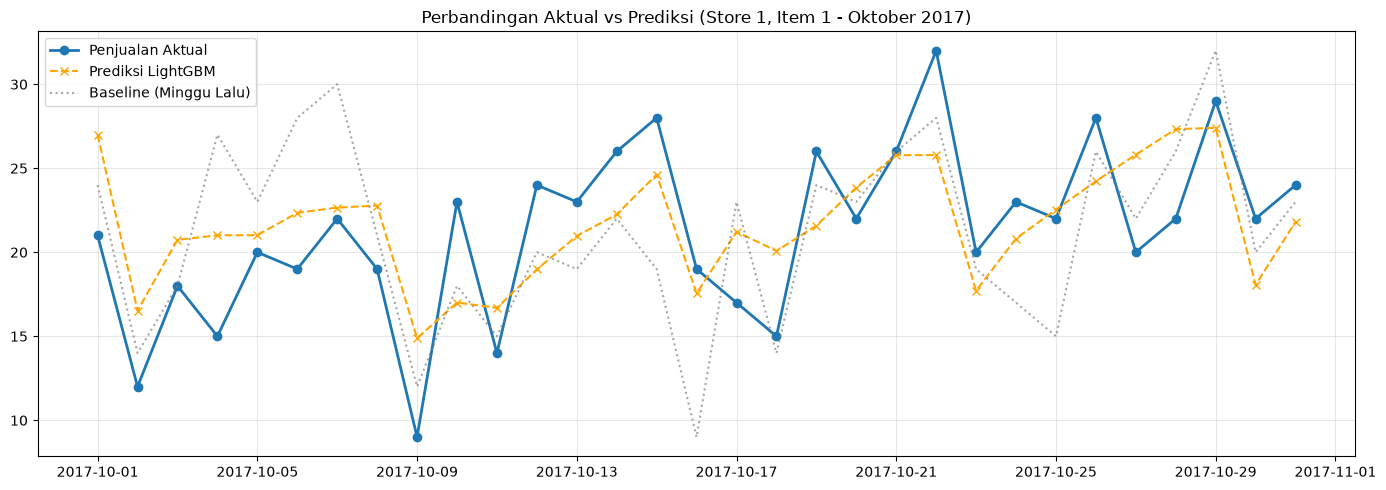

In [7]:
# 1. Cek Feature Importance
importances = pd.Series(model.feature_importances_, index=features).sort_values()
plt.figure(figsize=(10, 5))
importances.plot(kind='barh', color='teal')
plt.title('Feature Importance - LightGBM')
plt.xlabel('Seberapa sering fitur digunakan untuk memecah keputusan')
plt.tight_layout()
plt.show()

# 2. Visualisasi Prediksi vs Aktual (Store 1, Item 1 pada Oktober 2017)
val['pred_lgb'] = lgb_preds
sample_val = val[(val['store'] == 1) & (val['item'] == 1) & (val['date'] <= '2017-10-31')]

# Simpan tabel val ke dalam folder processed
val.to_parquet('../data/processed/val_predictions.parquet', index=False)
print("File val_predictions.parquet berhasil disimpan! Ukuran:", val.shape)

plt.figure(figsize=(14, 5))
plt.plot(sample_val['date'], sample_val['sales'], label='Penjualan Aktual', marker='o', linewidth=2)
plt.plot(sample_val['date'], sample_val['pred_lgb'], label='Prediksi LightGBM', linestyle='--', marker='x', color='orange')
plt.plot(sample_val['date'], sample_val['sales_lag_7'], label='Baseline (Minggu Lalu)', linestyle=':', color='gray', alpha=0.7)
plt.title('Perbandingan Aktual vs Prediksi (Store 1, Item 1 - Oktober 2017)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()